In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

In [2]:
df = pd.read_csv("Wholesale customers data.csv")      

F = ['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen']
X_bruto = df[F].values.astype(float)
canal   = df['Channel'].values

print("original:", X_bruto.shape)

original: (440, 6)


In [3]:
Xc    = X_bruto - X_bruto.mean(axis=0)
S_inv = np.linalg.inv(np.cov(Xc, rowvar=False))
d2    = np.einsum('ij,jk,ik->i', Xc, S_inv, Xc)

corte = chi2.ppf(0.975, df=6)
mask  = d2 <= corte

X_lim = X_bruto[mask]
y     = canal[mask]

print("corte = %.2f | removidos: %d | restantes: %d" % (corte, (~mask).sum(), mask.sum()))
print("Horeca:", (y==1).sum(), "| Retail:", (y==2).sum())

corte = 14.45 | removidos: 31 | restantes: 409
Horeca: 282 | Retail: 127


In [4]:
X = (X_lim - X_lim.mean(axis=0)) / X_lim.std(axis=0)
print(X.shape, "| média ~", X.mean(0).round(6)[:3], "| desvio ~", X.std(0).round(4)[:3])

(409, 6) | média ~ [-0. -0. -0.] | desvio ~ [1. 1. 1.]


## Implementação do t-SNE

Quatro peças:

1. `dist2` — distâncias euclidianas ao quadrado entre todos os pares
2. `p_condicional` — afinidades em alta dimensão (eq. 20.130). A perplexidade
   não fixa σ diretamente: para cada ponto é preciso resolver numericamente
   qual σ_i produz a entropia alvo, via busca binária.
3. `p_conjunto` — simetrização, p_ij = (p_j|i + p_i|j) / 2N (§20.4.10.2)
4. `tsne` — laço de otimização. Q usa a distribuição t com ν=1 (eq. 20.137),
   cuja cauda pesada resolve o crowding problem; o gradiente é a eq. 20.138.

In [5]:
def dist2(A):
    """matriz N×N de ||a_i - a_j||²"""
    s = (A**2).sum(1)
    return np.maximum(s[:, None] + s[None, :] - 2 * A @ A.T, 0)


def p_condicional(D, perplexidade, tol=1e-5, max_it=50):
    """busca binária do beta_i = 1/(2 sigma_i²) que atinge a perplexidade alvo"""
    N = D.shape[0]
    P = np.zeros((N, N))
    betas = np.zeros(N)
    logU = np.log(perplexidade)

    for i in range(N):
        beta, lo, hi = 1.0, -np.inf, np.inf
        Di = np.delete(D[i], i)

        for _ in range(max_it):
            Pi = np.exp(-Di * beta)
            soma = Pi.sum() or 1e-12
            H = np.log(soma) + beta * (Di * Pi).sum() / soma    
            Pi = Pi / soma
            dif = H - logU
            if abs(dif) < tol:
                break
            if dif > 0:                     
                lo = beta
                beta = beta * 2 if hi == np.inf else (beta + hi) / 2
            else:                            
                hi = beta
                beta = beta / 2 if lo == -np.inf else (beta + lo) / 2

        betas[i] = beta
        P[i, np.arange(N) != i] = Pi

    return P, betas


def p_conjunto(X, perplexidade):
    P, betas = p_condicional(dist2(X), perplexidade)
    P = (P + P.T) / (2 * len(X))
    return np.maximum(P, 1e-12), betas


def tsne(X, perplexidade=30, dims=2, n_iter=1000, lr=200.0,
         exagero=12.0, seed=0, verbose=True):
    rng = np.random.default_rng(seed)
    N = len(X)
    P, betas = p_conjunto(X, perplexidade)

    Z     = rng.normal(0, 1e-4, (N, dims))
    dZ    = np.zeros_like(Z)
    ganho = np.ones_like(Z)
    P_ex  = P * exagero

    for it in range(n_iter):
        Pat = P_ex if it < 250 else P                  

        num = 1.0 / (1.0 + dist2(Z))                   
        np.fill_diagonal(num, 0.0)
        Q = np.maximum(num / num.sum(), 1e-12)

        PQ   = (Pat - Q) * num                         
        grad = 4.0 * ((np.diag(PQ.sum(1)) - PQ) @ Z)

        mom   = 0.5 if it < 250 else 0.8
        ganho = np.where(np.sign(grad) != np.sign(dZ), ganho + 0.2, ganho * 0.8).clip(0.01)
        dZ    = mom * dZ - lr * ganho * grad
        Z     = Z + dZ
        Z     = Z - Z.mean(0)

        if verbose and it % 250 == 0:
            print("    iter %4d  KL = %.4f" % (it, (P * np.log(P / Q)).sum()))

    return Z, betas


In [6]:
Xc2 = X - X.mean(axis=0)
U, S, Vt = np.linalg.svd(Xc2, full_matrices=False)
Z_pca = Xc2 @ Vt[:2].T

print("PCA:", Z_pca.shape,
      "| variância explicada PC1+PC2: %.1f%%" % (100*(S[:2]**2).sum()/(S**2).sum()))

PCA: (409, 2) | variância explicada PC1+PC2: 69.5%


In [7]:
resultados = [("PCA (linear)", Z_pca)]
sigmas = {}

for perp in [5, 30, 100]:
    print("perplexidade", perp)
    Z, betas = tsne(X, perplexidade=perp, seed=0)
    resultados.append(("t-SNE  perplexity=%d" % perp, Z))
    sigmas[perp] = 1 / np.sqrt(2 * betas)

print("\nσ_i encontrados pela busca binária:")
for perp, s in sigmas.items():
    print("  perp %3d:  min %.3f   mediana %.3f   max %.3f" % (perp, s.min(), np.median(s), s.max()))

perplexidade 5
    iter    0  KL = 4.2105
    iter  250  KL = 3.5922
    iter  500  KL = 0.9187
    iter  750  KL = 0.7918
perplexidade 30
    iter    0  KL = 2.4591
    iter  250  KL = 2.7596
    iter  500  KL = 0.6602
    iter  750  KL = 0.6002
perplexidade 100
    iter    0  KL = 1.2575
    iter  250  KL = 2.1000
    iter  500  KL = 0.3428
    iter  750  KL = 0.3428

σ_i encontrados pela busca binária:
  perp   5:  min 0.056   mediana 0.258   max 1.523
  perp  30:  min 0.215   mediana 0.477   max 2.268
  perp 100:  min 0.436   mediana 0.707   max 2.957


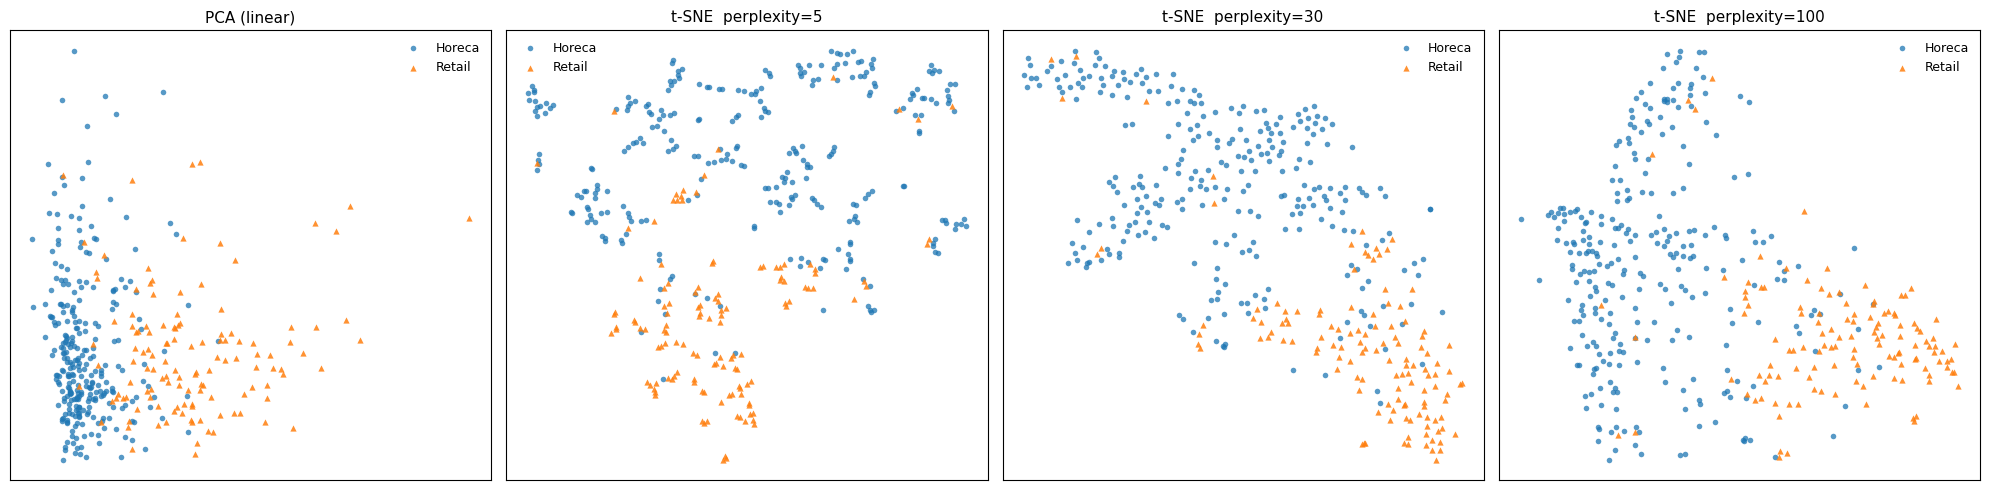

In [8]:
AZ, LA = "#1f77b4", "#ff7f0e"

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (tit, Z) in zip(axes, resultados):
    ax.scatter(Z[y==1, 0], Z[y==1, 1], s=16, c=AZ, marker="o", alpha=.75, lw=0, label="Horeca")
    ax.scatter(Z[y==2, 0], Z[y==2, 1], s=20, c=LA, marker="^", alpha=.85, lw=0, label="Retail")
    ax.set_title(tit, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

In [9]:
print("acurácia 5-NN (validação cruzada):")
for tit, Z in resultados:
    print("  %-26s %.3f" % (tit, cross_val_score(KNeighborsClassifier(5), Z, y, cv=5).mean()))
print("  %-26s %.3f" % ("(6 dimensões originais)",
                        cross_val_score(KNeighborsClassifier(5), X, y, cv=5).mean()))

acurácia 5-NN (validação cruzada):
  PCA (linear)               0.868
  t-SNE  perplexity=5        0.892
  t-SNE  perplexity=30       0.887
  t-SNE  perplexity=100      0.897
  (6 dimensões originais)    0.907


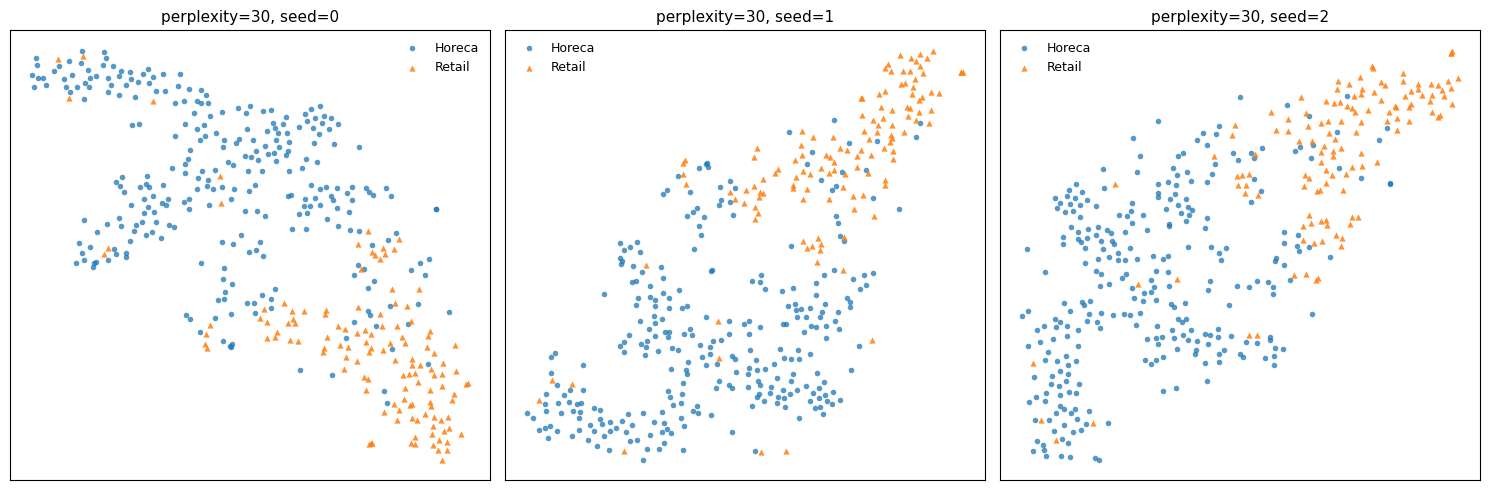

In [10]:
sementes = []
for s in [0, 1, 2]:
    Z, _ = tsne(X, perplexidade=30, seed=s, verbose=False)
    sementes.append(("seed=%d" % s, Z))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (tit, Z) in zip(axes, sementes):
    ax.scatter(Z[y==1, 0], Z[y==1, 1], s=16, c=AZ, marker="o", alpha=.75, lw=0, label="Horeca")
    ax.scatter(Z[y==2, 0], Z[y==2, 1], s=20, c=LA, marker="^", alpha=.85, lw=0, label="Retail")
    ax.set_title("perplexity=30, " + tit, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()